# 🥇 01 · Extract gold data from MetaTrader 5
### Extraer datos del oro desde MetaTrader 5

| | |
|---|---|
| 🍳 **Analogy / Analogía** | *Going to the market to buy ingredients* · *Ir al mercado a comprar los ingredientes* |
| 🎯 **Goal / Objetivo** | Download hourly (H1) gold candles · Descargar velas horarias (H1) del oro |
| 🏭 **Becomes / Se convierte en** | `src/data/extract.py` |

```
  MetaTrader 5 terminal ──(python API)──▶ pandas DataFrame ──▶ CSV file
       (your PC)                               (memory)          data/raw/
```

> ⚠️ **EN:** The `MetaTrader5` Python package only works on **Windows** with the terminal **open**.
> If it's not available, this notebook falls back to the small sample CSV stored in Git.
>
> ⚠️ **ES:** El paquete `MetaTrader5` solo funciona en **Windows** con la terminal **abierta**.
> Si no está disponible, el notebook usa el CSV de muestra guardado en Git.

In [1]:
import os
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.figsize"] = (11, 4)

## 1️⃣ Connect to the terminal / Conectarse a la terminal

In [2]:
try:
    import MetaTrader5 as mt5
    MT5_OK = mt5.initialize()
except ImportError:
    MT5_OK = False

if MT5_OK:
    info = mt5.terminal_info()
    print(f"✅ Connected to: {info.name} | company: {info.company}")
else:
    print("⚠️ MT5 not available → using data/sample/xauusd_h1_sample.csv")

✅ Connected to: MetaTrader 5 | company: MetaQuotes Ltd.


## 2️⃣ Find the gold symbol / Encontrar el símbolo del oro
**EN:** Every broker names gold differently: `XAUUSD`, `GOLD`, `XAUUSD.m`...
**ES:** Cada broker llama al oro distinto: `XAUUSD`, `GOLD`, `XAUUSD.m`...

In [3]:
if MT5_OK:
    gold_like = [s.name for s in mt5.symbols_get() if "XAU" in s.name or "GOLD" in s.name.upper()]
    print("Gold-like symbols at this broker:", gold_like)
    candidates = ["XAUUSD", "GOLD", "XAUUSD.m", "XAUUSDm"]
    SYMBOL = next(c for c in candidates if mt5.symbol_info(c) is not None)
    mt5.symbol_select(SYMBOL, True)
    print("👉 Using:", SYMBOL)

Gold-like symbols at this broker: ['GOLD', 'XAUEUR', 'BarrickGold', 'KinrossGold', 'SandstormGold', 'GoldenOcean', 'GoldmSachs', 'XAUCNH', 'XAUJPY', 'Gold Fields', 'GOLD24-7']
👉 Using: GOLD


## 3️⃣ How much history is there? / ¿Cuánta historia hay?
**EN:** We ask for a huge number of candles and see how many the broker actually has.
**ES:** Pedimos una cantidad enorme de velas y vemos cuántas tiene realmente el broker.

In [4]:
if MT5_OK:
    all_rates = mt5.copy_rates_from_pos(SYMBOL, mt5.TIMEFRAME_H1, 0, 100_000)
    first = pd.to_datetime(all_rates["time"][0], unit="s")
    last = pd.to_datetime(all_rates["time"][-1], unit="s")
    print(f"Available H1 candles: {len(all_rates):,}  ({first:%Y-%m-%d} → {last:%Y-%m-%d})")

Available H1 candles: 82,526  (2001-06-04 → 2026-09-29)


## 4️⃣ Download the last 30,000 candles (~5 years) / Descargar las últimas 30.000 velas

**EN — Why not all the history?** Markets change. Gold in 2005 behaved differently from gold today
(different volatility, liquidity, trading hours). ~5 years gives plenty of examples while staying relevant.

**ES — ¿Por qué no toda la historia?** Los mercados cambian. El oro en 2005 se comportaba distinto al de hoy
(otra volatilidad, liquidez, horarios). ~5 años dan muchos ejemplos y siguen siendo relevantes.

In [5]:
if MT5_OK:
    rates = mt5.copy_rates_from_pos(SYMBOL, mt5.TIMEFRAME_H1, 0, 30_000)
    mt5.shutdown()
    df = pd.DataFrame(rates)
    df["time"] = pd.to_datetime(df["time"], unit="s")
    df = df.rename(columns={"tick_volume": "volume"})[["time", "open", "high", "low", "close", "volume", "spread"]]
    df = df.iloc[:-1]  # last candle is still forming → drop it / aún se está formando → fuera
else:
    df = pd.read_csv("data/sample/xauusd_h1_sample.csv", parse_dates=["time"])

print(df.shape)
df.tail()

(29999, 7)


,time,open,high,low,close,volume,spread
29994,2026-09-29 02:00:00,4121.36,4128.79,4121.11,4127.13,5306,40
29995,2026-09-29 03:00:00,4127.12,4127.74,4114.24,4117.59,15623,40
29996,2026-09-29 04:00:00,4117.54,4136.83,4113.16,4135.03,19695,40
29997,2026-09-29 05:00:00,4135.01,4138.98,4126.31,4137.35,13425,40
29998,2026-09-29 06:00:00,4137.24,4140.24,4131.28,4133.63,8990,40


### 🕯️ What is a candle? / ¿Qué es una vela?
```
       high ─┬─        Each row = 1 hour of trading
             │         Cada fila = 1 hora de mercado
      ┌──────┴──┐ close   (green: close > open → price went UP)
      │  body   │         (verde: cierre > apertura → SUBIÓ)
      └──────┬──┘ open
             │
       low  ─┴─
```

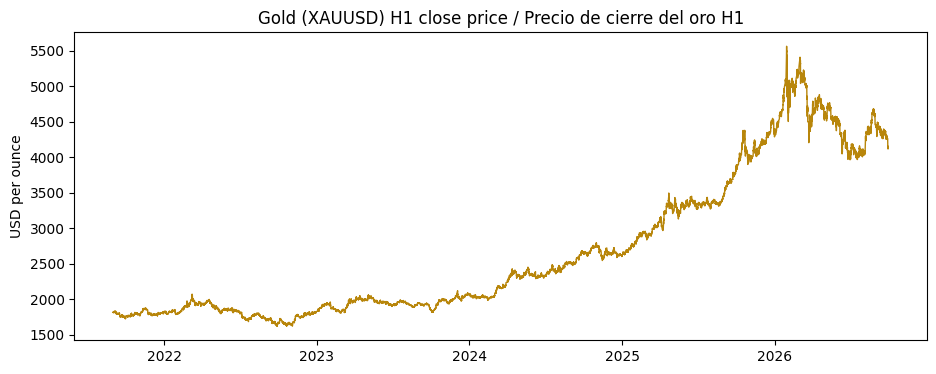

In [6]:
fig, ax = plt.subplots()
ax.plot(df["time"], df["close"], color="#b8860b", lw=1)
ax.set_title("Gold (XAUUSD) H1 close price / Precio de cierre del oro H1")
ax.set_ylabel("USD per ounce")
plt.show()

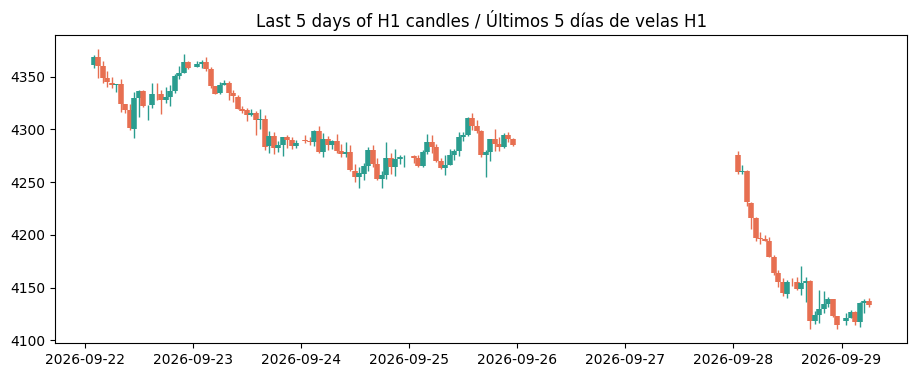

In [7]:
last_week = df.tail(24 * 5)
fig, ax = plt.subplots()
colors = ["#2a9d8f" if c >= o else "#e76f51" for o, c in zip(last_week.open, last_week.close, strict=True)]
ax.vlines(last_week.time, last_week.low, last_week.high, color=colors, lw=1)
ax.vlines(last_week.time, last_week.open, last_week.close, color=colors, lw=4)
ax.set_title("Last 5 days of H1 candles / Últimos 5 días de velas H1")
plt.show()

---
## 🔁 From notebook to production / Del notebook a producción

| Notebook cell (exploration) | Production code (`src/data/extract.py`) |
|---|---|
| `mt5.initialize()` + prints | `fetch_rates()` raises a clear error if the terminal is closed |
| Hard-coded `["XAUUSD","GOLD"...]` | `params.yaml → data.symbol_candidates` |
| `30_000` typed by hand | `params.yaml → data.n_bars` |
| DataFrame lives in memory | Saved to `data/raw/xauusd_h1.csv` and **versioned with DVC** |
| Run by clicking ▶ | `dvc repro extract` (or `python -m src.data.extract --sample`) |

**EN:** The notebook is where we *discover*; the `.py` is what we *repeat* reliably.
**ES:** El notebook es donde *descubrimos*; el `.py` es lo que *repetimos* de forma confiable.